In [1]:
# Experiment 07 — Quantum Support Vector Machine Using Quantum Kernel

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [3]:
# Create a small two-feature dataset
X_train = np.array([
    [0.1, 0.2],
    [0.2, 0.4],
    [0.3, 0.1],
    [1.2, 1.4],
    [1.4, 1.1],
    [1.5, 1.5]
])

y_train = np.array([0, 0, 0, 1, 1, 1])

X_test = np.array([
    [0.2, 0.3],
    [0.4, 0.2],
    [1.3, 1.2],
    [1.4, 1.4]
])

y_test = np.array([0, 0, 1, 1])

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 6
Testing Samples: 4


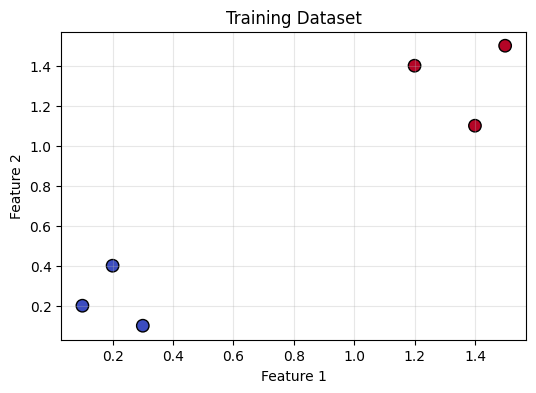

In [4]:
# Plot the training samples
plt.figure(figsize=(6, 4))

plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    cmap="coolwarm",
    s=80,
    edgecolors="black"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Training Dataset")
plt.grid(alpha=0.3)
plt.show()

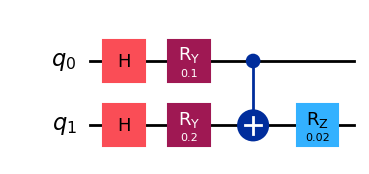

In [5]:
# Encode two classical features into two qubits
def feature_map(x):
    qc = QuantumCircuit(2)

    qc.h([0, 1])

    qc.ry(x[0], 0)
    qc.ry(x[1], 1)

    qc.cx(0, 1)
    qc.rz(x[0] * x[1], 1)

    return qc

# Display a sample feature map
sample_circuit = feature_map(X_train[0])

display(sample_circuit.draw("mpl"))

In [6]:
# Calculate similarity between quantum states
def quantum_kernel(x1, x2):
    state1 = Statevector.from_instruction(feature_map(x1))
    state2 = Statevector.from_instruction(feature_map(x2))

    return float(abs(np.vdot(state1.data, state2.data)) ** 2)

# Calculate the training kernel matrix
K_train = np.array([
    [quantum_kernel(x1, x2) for x2 in X_train]
    for x1 in X_train
])

print("Quantum Kernel Matrix:")
print(np.round(K_train, 3))

Quantum Kernel Matrix:
[[1.    0.987 0.988 0.328 0.351 0.306]
 [0.987 1.    0.975 0.419 0.44  0.392]
 [0.988 0.975 1.    0.353 0.381 0.332]
 [0.328 0.419 0.353 1.    0.967 0.972]
 [0.351 0.44  0.381 0.967 1.    0.953]
 [0.306 0.392 0.332 0.972 0.953 1.   ]]


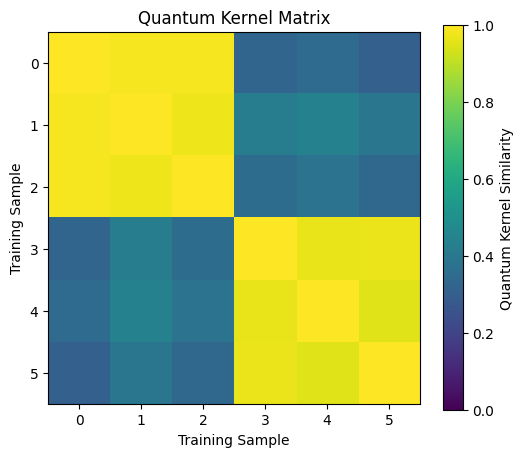

In [7]:
# Display the kernel matrix
plt.figure(figsize=(6, 5))

plt.imshow(K_train, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="Quantum Kernel Similarity")

plt.title("Quantum Kernel Matrix")
plt.xlabel("Training Sample")
plt.ylabel("Training Sample")

plt.show()

In [9]:
# Train SVM using the quantum kernel
qsvm = SVC(kernel="precomputed")

qsvm.fit(K_train, y_train)

print("Quantum SVM Training Completed")
print("Support Vectors:", qsvm.support_)

Quantum SVM Training Completed
Support Vectors: [1 2 3 4]


In [10]:
# Calculate the testing kernel matrix
K_test = np.array([
    [quantum_kernel(x1, x2) for x2 in X_train]
    for x1 in X_test
])

# Predict the test labels
y_pred = qsvm.predict(K_test)

accuracy = accuracy_score(y_test, y_pred)

print("Actual Labels:", y_test)
print("Predicted Labels:", y_pred)
print("Accuracy:", round(accuracy * 100, 2), "%")

Actual Labels: [0 0 1 1]
Predicted Labels: [0 0 1 1]
Accuracy: 100.0 %


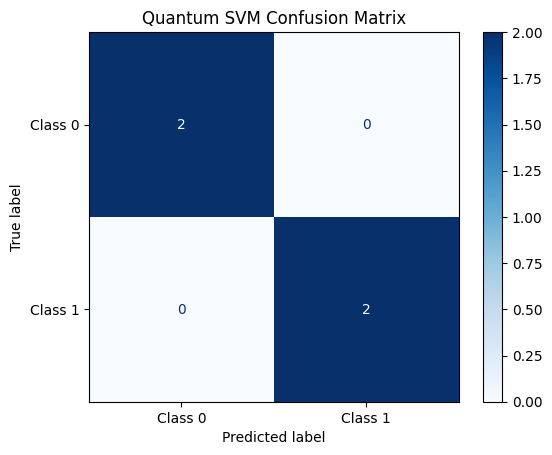

In [11]:
# Display classification results
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1"]
).plot(cmap="Blues")

plt.title("Quantum SVM Confusion Matrix")
plt.show()